In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

CIBLE = "TousAge_allergie_urgences"
EXOS  = ['As in PM10', 'BaP in PM10', 'Cd in PM10',
       'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
       'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1',
       'pression_mer', 'tendance_pression_3h', 
       'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite',
       'pression_station', 'precipitation_3h', 'tp_averses_ou_orages',
       'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers',
       'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure',
       'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages',
       'tp_tempete_poussiere_chasse_neige', 'TousAge_asthme_urgences', 'TousAge_asthme_hospitalisation', 
       '0an_bronchiolite_urgences', 'TousAge_allergie_hospitalisation', 
       'prev_calc_Maladie_Respi_Chronique_0-14_9',
       'prev_calc_Maladie_Respi_Chronique_15-64_9',
       'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain',
       #'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes',
       #'pct_ouvriers', 'pct_retraites', 'pct_agriculteurs', 
       'densite_generalistes', 'densite_pediatres',
       'densite_pneumologues', 'densite_allergologues', 'densite_kines',
       'sos_present']

H     = 4                                   # nombre de semaines futures moyennées

# --- Une ligne par département et par semaine t : cible = moyenne de y(t+1)..y(t+H) ---
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")
    y, sem = d[CIBLE], d.index.isocalendar().week.astype(float)
    moy_glis = y.rolling(H, min_periods=H).mean()          # moyenne de y(t-H+1)..y(t), NaN si un trou
    morceaux.append(pd.DataFrame({
        "code_dept": dept,
        "date_debut": d.index + pd.Timedelta(weeks=1),      # première semaine de la fenêtre cible
        "date_fin":   d.index + pd.Timedelta(weeks=H),      # dernière semaine de la fenêtre cible
        "cible":      moy_glis.shift(-H),                   # moyenne de y(t+1)..y(t+H)
        "y_passe":    moy_glis,                             # moyenne des H dernières semaines connues
        "y_lag0": y, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "sem_sin": np.sin(2 * np.pi * sem / 52.18),
        "sem_cos": np.cos(2 * np.pi * sem / 52.18),
        **{c: d[c] for c in EXOS},
    }))
panel = pd.concat(morceaux).dropna(subset=["cible", "y_passe", "y_lag0", "y_lag1", "y_lag2"])

# --- Split sur l'année de la DERNIÈRE semaine de la fenêtre (pas de chevauchement train/val) ---
an = panel["date_fin"].dt.year
panel["split"] = np.select([an <= 2022, an == 2023], ["train", "val"], default="test")

# --- Baselines sur la même cible agrégée ---
# 1) persistance : la moyenne des H semaines à venir vaut celle des H semaines passées
panel["base_persist"] = panel["y_passe"]
# 2) profil saisonnier : moyenne de la cible sur le train, par département et semaine de début
panel["sem_debut"] = panel["date_debut"].dt.isocalendar().week.astype(int)
profil = (panel[panel["split"] == "train"]
          .groupby(["code_dept", "sem_debut"])["cible"].mean().rename("base_saison"))
panel = panel.join(profil, on=["code_dept", "sem_debut"])

def scores(y_vrai, y_pred):
    return {"R2": r2_score(y_vrai, y_pred),
            "MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5}

val = panel[panel["split"] == "val"].dropna(subset=["base_saison"])
print(panel["split"].value_counts())
print("Persistance :", scores(val["cible"], val["base_persist"]))
print("Profil sais.:", scores(val["cible"], val["base_saison"]))

split
train    9312
val      4992
test     4992
Name: count, dtype: int64
Persistance : {'R2': 0.4967283399499325, 'MAE': 137.7757102455767, 'RMSE': 185.5121233845118}
Profil sais.: {'R2': 0.6018206564827504, 'MAE': 122.60529285462464, 'RMSE': 165.01005986809272}


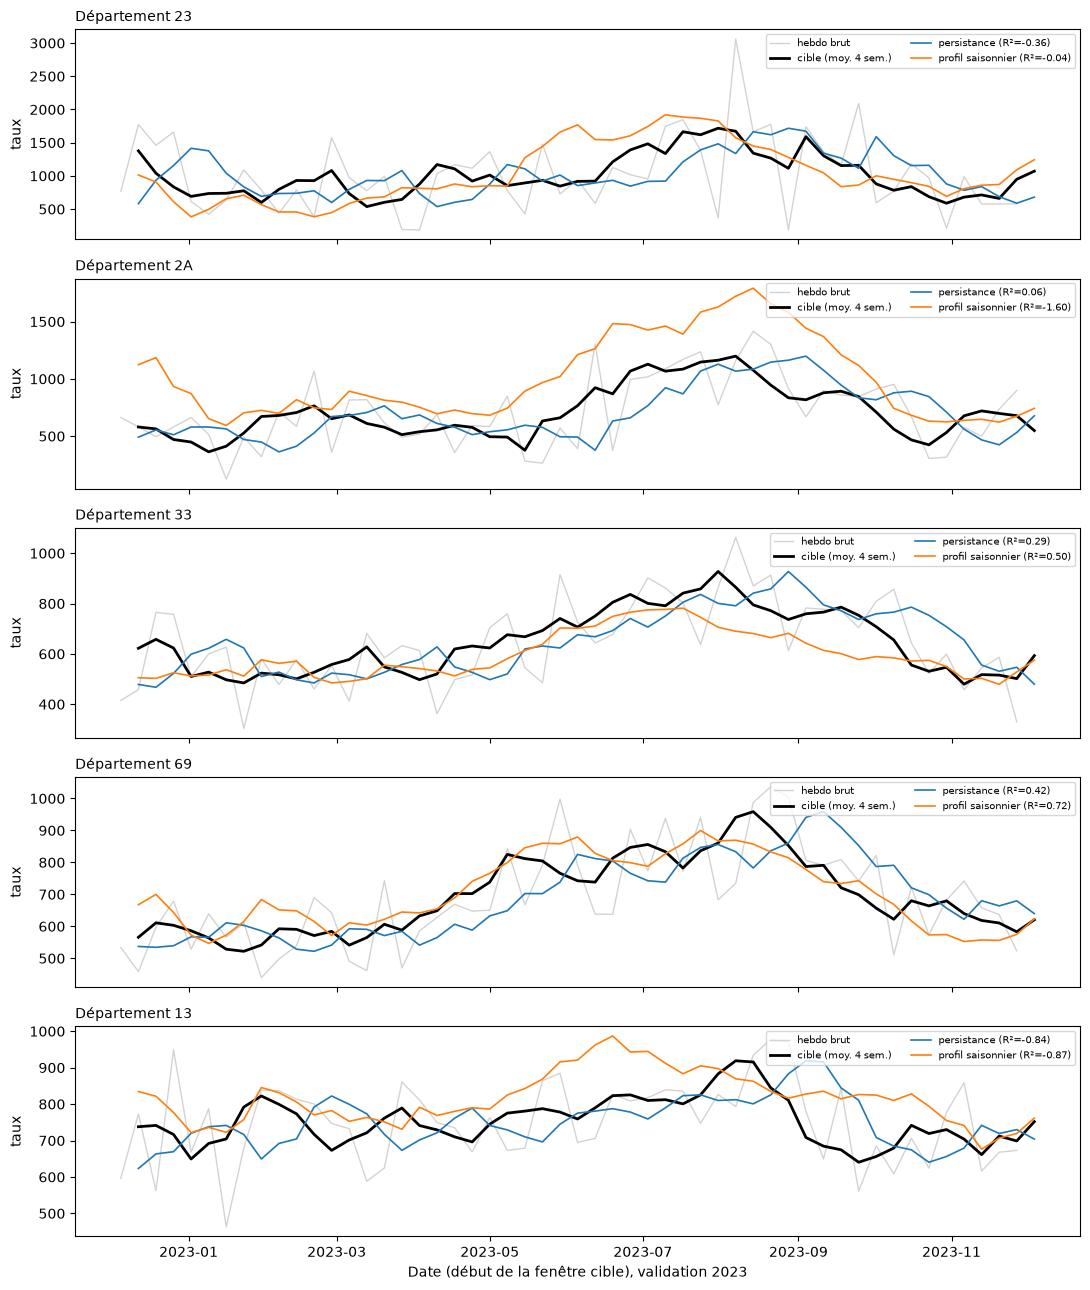

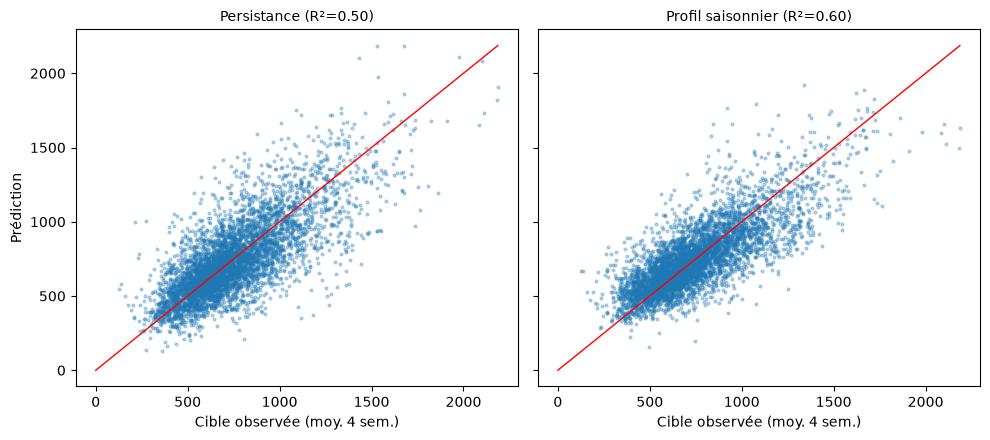

In [2]:
DEPTS = ["23", "2A", "33", "69", "13"]          # départements à afficher

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = val[val["code_dept"] == dept].sort_values("date_debut")
    sc_p = scores(v["cible"], v["base_persist"])["R2"]
    sc_s = scores(v["cible"], v["base_saison"])["R2"]
    # valeur hebdomadaire brute de la semaine t (y_lag0), placée à sa propre date
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["date_debut"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    ax.plot(v["date_debut"], v["base_persist"], color="tab:blue", lw=1.2,
            label=f"persistance (R²={sc_p:.2f})")
    ax.plot(v["date_debut"], v["base_saison"], color="tab:orange", lw=1.2,
            label=f"profil saisonnier (R²={sc_s:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (début de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# --- Vue d'ensemble, tous départements : prédit vs observé ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, col, nom in zip(axes, ["base_persist", "base_saison"], ["Persistance", "Profil saisonnier"]):
    ax.scatter(val["cible"], val[col], s=4, alpha=0.3)
    lim = [0, val[["cible", col]].max().max()]
    ax.plot(lim, lim, color="red", lw=1)                 # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(val['cible'], val[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

#FEATURES = ["profil", "y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos", "code_dept"] + EXOS

FEATURES = ["y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos"] + EXOS
CAT = []
NUM = [c for c in FEATURES if c not in CAT]

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT),
])
modele = Pipeline([("prep", prep), ("reg", LinearRegression())])

train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible"])

modele.fit(train[FEATURES], train["cible"])
print("LR val :", scores(val_m["cible"], modele.predict(val_m[FEATURES])))

LR val : {'R2': 0.6359613051266323, 'MAE': 117.57711226382987, 'RMSE': 157.55840725962784}


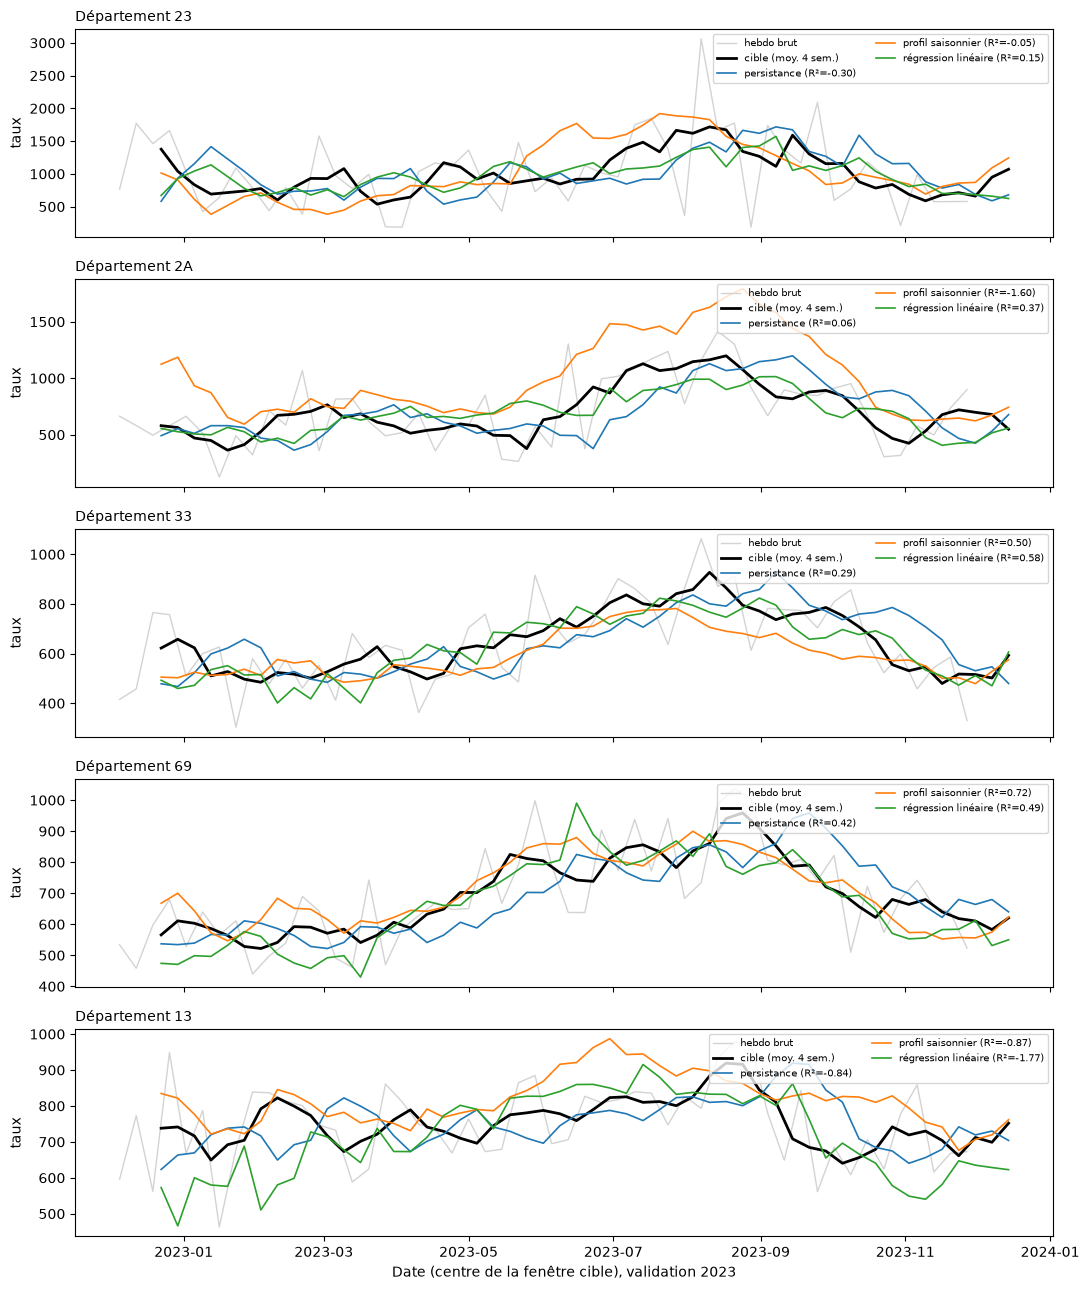

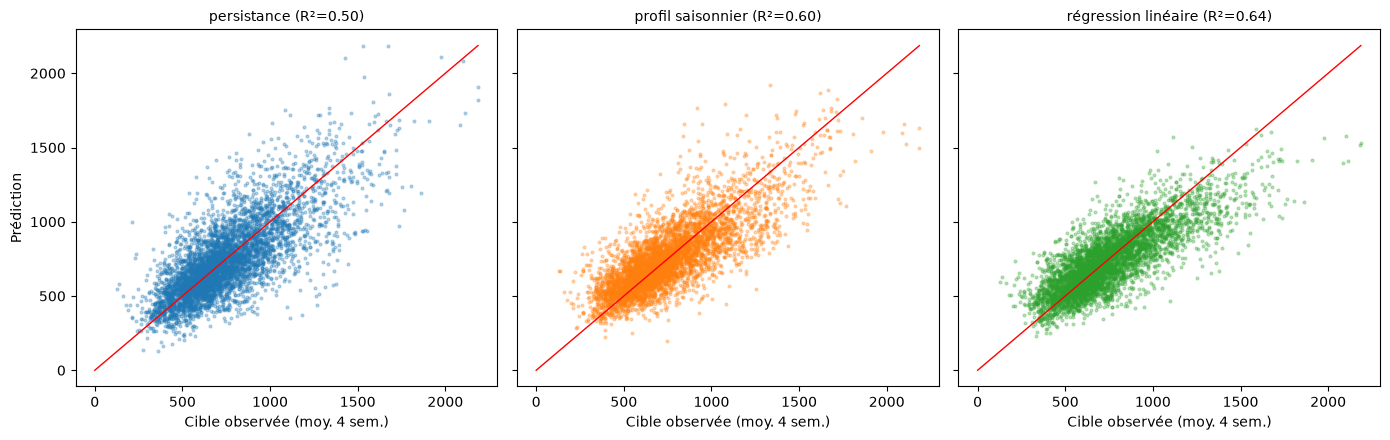

In [4]:
import matplotlib.pyplot as plt

# Prédictions du modèle sur la validation, mêmes lignes que les baselines
v_all = val_m.dropna(subset=["base_saison"]).copy()
v_all["pred_LR"] = modele.predict(v_all[FEATURES])
v_all["centre"] = v_all["date_debut"] + pd.Timedelta(weeks=(H - 1) / 2)

SERIES = [("base_persist", "persistance", "tab:blue"),
          ("base_saison",  "profil saisonnier", "tab:orange"),
          ("pred_LR",      "régression linéaire", "tab:green")]

# --- Séries temporelles par département ---
fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = v_all[v_all["code_dept"] == dept].sort_values("date_debut")
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["centre"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    for col, nom, coul in SERIES:
        r2 = scores(v["cible"], v[col])["R2"]
        ax.plot(v["centre"], v[col], color=coul, lw=1.2, label=f"{nom} (R²={r2:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (centre de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# --- Vue d'ensemble, tous départements : prédit vs observé ---
fig, axes = plt.subplots(1, len(SERIES), figsize=(14, 4.5), sharex=True, sharey=True)
lim = [0, v_all[["cible"] + [c for c, _, _ in SERIES]].max().max()]
for ax, (col, nom, coul) in zip(axes, SERIES):
    ax.scatter(v_all["cible"], v_all[col], s=4, alpha=0.3, color=coul)
    ax.plot(lim, lim, color="red", lw=1)                   # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(v_all['cible'], v_all[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [5]:
from scipy import stats

POLLUT = ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10',
          'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1']
METEO  = ['pression_mer', 'tendance_pression_3h', 'vent_vitesse', 'temperature_kelvin',
          'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h',
          'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers',
          'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure',
          'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages',
          'tp_tempete_poussiere_chasse_neige']

def correlations_exos(dept, lag, splits=("train",), variables=METEO + POLLUT):
    """Corrélation de chaque exogène désaisonnalisé de la semaine t-lag avec le résidu
    du modèle persistance + saison sur y(t+1), pour un département."""
    d = panel[panel["code_dept"] == dept].sort_index().asfreq("W-MON")
    x = d[variables].shift(lag)
    y = d["cible"]
    garde = d["split"].isin(splits)

    sem = pd.Series(d.index.isocalendar().week.values, index=d.index)
    saison_cible = sem.map(y[garde].groupby(sem[garde]).mean())
    saison_passe = sem.map(d["y_passe"][garde].groupby(sem[garde]).mean())
    y = y - (saison_cible + (d["y_passe"] - saison_passe))
    x = x - x[garde].groupby(sem[garde]).mean().reindex(sem.values).set_axis(x.index)

    lignes = []
    for v in variables:
        m = garde & x[v].notna() & y.notna()
        if m.sum() < 10 or x.loc[m, v].std() == 0:
            lignes.append({"variable": v, "n": int(m.sum()), "r_pearson": np.nan,
                           "p_pearson": np.nan, "rho_spearman": np.nan})
            continue
        r, p = stats.pearsonr(x.loc[m, v], y[m])
        rho, _ = stats.spearmanr(x.loc[m, v], y[m])
        lignes.append({"variable": v, "n": int(m.sum()), "r_pearson": r,
                       "p_pearson": p, "rho_spearman": rho})

    res = pd.DataFrame(lignes).set_index("variable")
    res["groupe"] = ["météo" if v in METEO else "pollution" for v in res.index]
    return res.reindex(res["r_pearson"].abs().sort_values(ascending=False).index).round(3)

In [6]:
LAGS, SEUIL = range(0, 3), 0.5

table = pd.DataFrame(index=sorted(panel["code_dept"].unique()), columns=list(LAGS))
for dept in table.index:
    for lag in LAGS:
        res = correlations_exos(dept, lag)
        sel = res[res["r_pearson"].abs() > SEUIL]
        table.loc[dept, lag] = ", ".join(f"{v} ({r:+.2f})" for v, r in sel["r_pearson"].items()) or np.nan

table.columns.name, table.index.name = "lag", "code_dept"

display(table.value_counts())

0                   1                                2                                     
Ni in PM10 (+0.58)  Ni in PM10 (+0.59), NO2 (+0.53)  Ni in PM10 (+0.58)                        1
As in PM10 (-0.52)  As in PM10 (-0.61)               As in PM10 (-0.68), Pb in PM10 (-0.57)    1
Name: count, dtype: int64

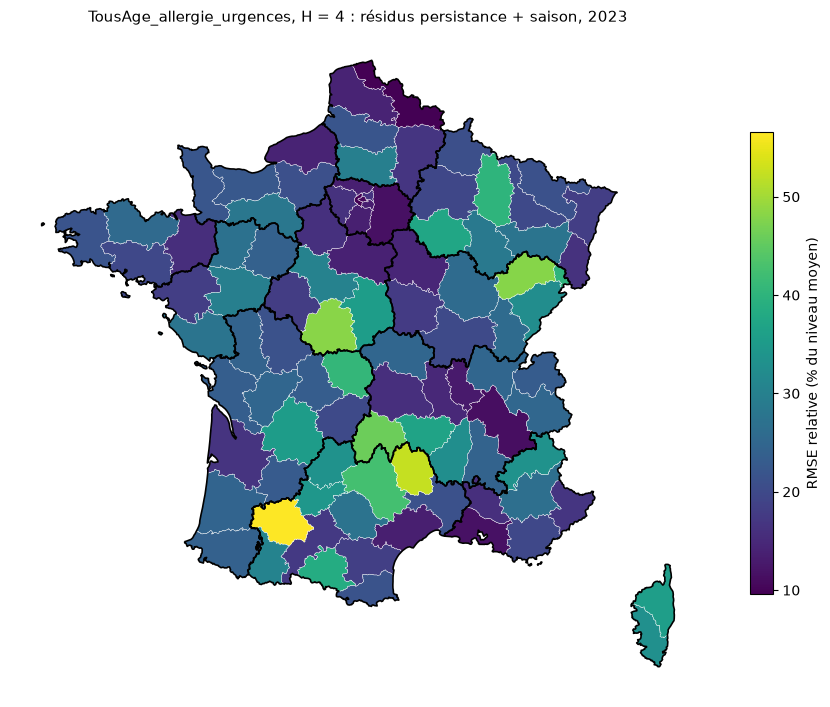

code         nom  observe  rmse_rel
  32        Gers    532.9      56.5
  48      Lozère    696.0      52.4
  36       Indre    905.6      48.2
  70 Haute-Saône    683.9      47.9
  15      Cantal    791.8      46.0
  12     Aveyron    772.5      42.6
  23      Creuse   1007.2      40.6
  55       Meuse    843.6      40.1


In [7]:
import geopandas as gpd

REGIONS = {
    "ARA": ["01","03","07","15","26","38","42","43","63","69","73","74"],
    "BFC": ["21","25","39","58","70","71","89","90"],
    "BRE": ["22","29","35","56"],
    "CVL": ["18","28","36","37","41","45"],
    "COR": ["2A","2B"],
    "GES": ["08","10","51","52","54","55","57","67","68","88"],
    "HDF": ["02","59","60","62","80"],
    "IDF": ["75","77","78","91","92","93","94","95"],
    "NOR": ["14","27","50","61","76"],
    "NAQ": ["16","17","19","23","24","33","40","47","64","79","86","87"],
    "OCC": ["09","11","12","30","31","32","34","46","48","65","66","81","82"],
    "PDL": ["44","49","53","72","85"],
    "PAC": ["04","05","06","13","83","84"],
}
dept_region = {d: r for r, ds in REGIONS.items() for d in ds}

URL = ("https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/"
       "departements-version-simplifiee.geojson")
carte = gpd.read_file(URL)[["code", "nom", "geometry"]]
carte["region"] = carte["code"].map(dept_region)
regions = carte[["region", "geometry"]].dissolve(by="region")

p = panel.copy()
p["sem"] = p.index.isocalendar().week.values
prof = (p[p["split"] == "train"].groupby(["code_dept", "sem"])[["cible", "y_passe"]]
        .mean().add_prefix("saison_"))
p = p.join(prof, on=["code_dept", "sem"])
p["residu"] = p["cible"] - (p["saison_cible"] + (p["y_passe"] - p["saison_y_passe"]))

q = p[p["split"] == "val"].dropna(subset=["residu"])
g = q.groupby("code_dept")
res = pd.DataFrame({"observe":  g["cible"].mean(),
                    "rmse_rel": 100 * np.sqrt((q["residu"] ** 2).groupby(q["code_dept"]).mean())
                                / g["cible"].mean()})
carte = carte.merge(res, left_on="code", right_index=True, how="left")

fig, ax = plt.subplots(figsize=(9, 8))
carte.plot(column="rmse_rel", cmap="viridis", legend=True, ax=ax, edgecolor="white", linewidth=0.3,
           missing_kwds={"color": "lightgrey", "label": "sans donnée"},
           legend_kwds={"shrink": 0.6, "label": "RMSE relative (% du niveau moyen)"})
regions.boundary.plot(ax=ax, color="black", linewidth=1.2)
ax.set_title(f"{CIBLE}, H = {H} : résidus persistance + saison, 2023", fontsize=11)
ax.set_axis_off()
plt.tight_layout()
plt.show()

cols = ["code", "nom", "observe", "rmse_rel"]
print(carte.nlargest(8, "rmse_rel")[cols].round(1).to_string(index=False))

In [8]:
res.join(panel.groupby("code_dept")["pct_urbain"].first()).corr(method="spearman")

,observe,rmse_rel,pct_urbain
observe,1.000000,-0.047341,-0.255012
rmse_rel,-0.047341,1.000000,-0.664252
pct_urbain,-0.255012,-0.664252,1.000000


In [9]:
import re, unicodedata

LAGS = range(0, 3)

STATION_DEPT = {"AGEN": "47", "AIXENPROVENCE": "13", "AJACCIO": "2A", "ALES": "30",
    "AMBERIEU": "01", "AMIENS": "80", "ANGERS": "49", "ANGOULEME": "16", "ANNECY": "74",
    "ANNEMASSE": "74", "ANTONY": "92", "AURILLAC": "15", "AUXERRE": "89", "AVIGNON": "84",
    "BAGNOLS": "30", "BART": "25", "BAYONNE": "64", "BERRIAS": "07", "BESANCON": "25",
    "BLETTERANS": "39", "BORDEAUX": "33", "BORDEAUXBASSENS": "33", "BORDEAUXPESSAC": "33",
    "BOURGENBRESSE": "01", "BOURGES": "18", "BOURGOINJALLIEU": "38", "BRESTREG": "29",
    "BRIANCON": "05", "BRUSSIEULANZONI": "69", "CAEN": "14", "CASTRES": "81",
    "CHALONSURSAONE": "71", "CHAMBERY": "73", "CHARLEVILLE": "08", "CHAUMONT": "52",
    "CHOLET": "49", "CLERMONTFERRAND": "63", "CORTE": "2B", "COUX": "07", "DIEULEFIT": "26",
    "DIJON": "21", "DINAN": "22", "DOLE": "39", "DRAGUIGNAN": "83", "DURAS": "47",
    "FONTROMEU": "66", "FUMEL": "47", "GAP": "05", "GENAS": "69", "GLEIZE": "69", "GONESSE": "95",
    "GRENOBLE": "38", "LABOURBOULE": "63", "LAFERTEMACE": "61", "LAFLECHE": "72",
    "LAROCHELLE": "17", "LAROCHESURYON": "85", "LEMANS": "72", "LEPUYENVELAY": "43", "LILLE": "59",
    "LIMOGES": "87", "LORIENT": "56", "LURE": "70", "LYON": "69", "LYONSITE": "69",
    "LYONWESTCRAPONNE": "69", "MACON": "71", "MAREUIL": "24", "MARSEILLE": "13", "MELUN": "77",
    "METZ": "57", "MILLAU": "12", "MONTDEMARSAN": "40", "MONTLUCON": "03", "MONTPELLIER": "34",
    "MULHOUSE": "68", "NANCY": "54", "NANTES": "44", "NARBONNE": "11", "NERAC": "47",
    "NEVERS": "58", "NICE": "06", "NIMES": "30", "NIORT": "79", "ORLEANS": "45", "PARIS": "75",
    "PAU": "64", "PERIGEUX": "24", "PERPIGNAN": "66", "PICDUMIDI": "65", "POITIERS": "86",
    "PONTIVY": "56", "REIMS": "51", "RENNES": "35", "ROANNE": "42", "ROUEN": "76",
    "ROUSSILLON": "38", "RUFFEC": "16", "SACLAY": "91", "SAINTALBANAURIOLLES": "07",
    "SAINTBRIEUC": "22", "SAINTDIEDESVOSGES": "88", "SAINTEFOYLESLYON": "69", "SAINTETIENNE": "42",
    "SAINTOMER": "62", "SAINTQUENTINENYVELINES": "78", "SEDAN": "08", "SIGNYLABBAYE": "08",
    "STGENIS": "69", "STQUENTIN": "02", "STRASBOURG": "67", "TARBES": "65", "TOULON": "83",
    "TOULOUSE": "31", "TOURS": "37", "TROYES": "10", "TULLE": "19", "VALDAHON": "25",
    "VALENCE": "26", "VERNETLESBAINS": "66", "VICHY": "03", "VILLENEUVEDASCQ": "59"}

def norm(nom):
    nom = unicodedata.normalize("NFKD", str(nom)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Z]", "", nom.upper())

pol = pd.read_csv("../data/processed/POLLEN2023.csv", sep=";", decimal=",")
pol = pol.rename(columns={pol.columns[0]: "date"})
pol["date"] = pd.to_datetime(pol["date"])
pol = pol.melt(id_vars="date", var_name="ville", value_name="pollen")
pol["code_dept"] = pol["ville"].map(norm).map(STATION_DEPT)
print("Villes sans département :", sorted(pol.loc[pol["code_dept"].isna(), "ville"].unique()))

pol_h = (pol.dropna(subset=["code_dept", "pollen"])
         .groupby(["code_dept", pd.Grouper(key="date", freq="W-MON", label="left", closed="left")])
         ["pollen"].agg(["mean", "count"]))
pol_h = pol_h.loc[pol_h["count"] >= 4, "mean"].rename("pollen").reset_index()

p = panel.copy()
p["sem"] = p.index.isocalendar().week.values
prof = (p[p["split"] == "train"].groupby(["code_dept", "sem"])[["cible", "y_passe"]]
        .mean().add_prefix("saison_"))
p = p.join(prof, on=["code_dept", "sem"])
p["residu"] = p["cible"] - (p["saison_cible"] + (p["y_passe"] - p["saison_y_passe"]))
r23 = p.loc[p["split"] == "val", ["code_dept", "residu"]].rename_axis("date").reset_index()

lignes = []
for dept, pd_ in pol_h.groupby("code_dept"):
    x = pd_.set_index("date")["pollen"].asfreq("W-MON")
    r = r23[r23["code_dept"] == dept].set_index("date")["residu"]
    if r.empty:
        continue
    ligne = {"code_dept": dept}
    for lag in LAGS:
        xl = x.shift(lag).reindex(r.index)
        ligne[f"lag{lag}"] = r.corr(xl, method="spearman")
        ligne[f"n{lag}"] = int((r.notna() & xl.notna()).sum())
    lignes.append(ligne)

cor_pollen = pd.DataFrame(lignes).set_index("code_dept").round(2)
with pd.option_context("display.max_rows", None):
    display(cor_pollen)

Villes sans département : []


,lag0,n0,lag1,n1,lag2,n2
code_dept,,,,,,
01,-0.05,38,0.13,37,0.30,37
15,0.20,16,0.48,15,0.21,15
16,0.26,38,0.18,37,0.13,36
2A,-0.16,29,-0.23,28,-0.31,27
49,0.37,26,0.31,25,-0.02,24
74,-0.12,25,-0.19,24,-0.15,23
80,-0.55,19,-0.37,18,-0.20,17
84,0.03,32,-0.02,31,0.03,30
92,-0.16,31,-0.28,30,-0.26,29


In [10]:
MOIS_SAISON = [4, 5, 6, 7, 8]

lignes = []
for dept, pd_ in pol_h.groupby("code_dept"):
    x = pd_.set_index("date")["pollen"].asfreq("W-MON")
    y = (df[df["code_dept"] == dept].drop_duplicates("date").set_index("date")[CIBLE]
         .loc["2023"])
    y = y[y.index.month.isin(MOIS_SAISON)]
    ligne = {"code_dept": dept}
    for lag in LAGS:
        xl = x.shift(lag).reindex(y.index)
        ligne[f"lag{lag}"] = y.corr(xl, method="spearman")
        ligne[f"n{lag}"] = int((y.notna() & xl.notna()).sum())
    lignes.append(ligne)

cor_brut = pd.DataFrame(lignes).set_index("code_dept").round(2)
display(cor_brut)

,lag0,n0,lag1,n1,lag2,n2
code_dept,,,,,,
01,-0.61,22,-0.62,22,-0.56,22
15,0.57,14,0.38,14,0.65,14
16,0.03,22,0.16,22,0.33,22
2A,-0.49,22,-0.44,22,-0.27,22
49,0.23,19,0.30,19,0.43,19
74,0.24,21,0.14,20,0.16,19
80,0.16,17,-0.01,16,0.20,15
84,-0.51,22,-0.38,22,-0.31,21
92,0.57,22,0.60,22,0.48,22


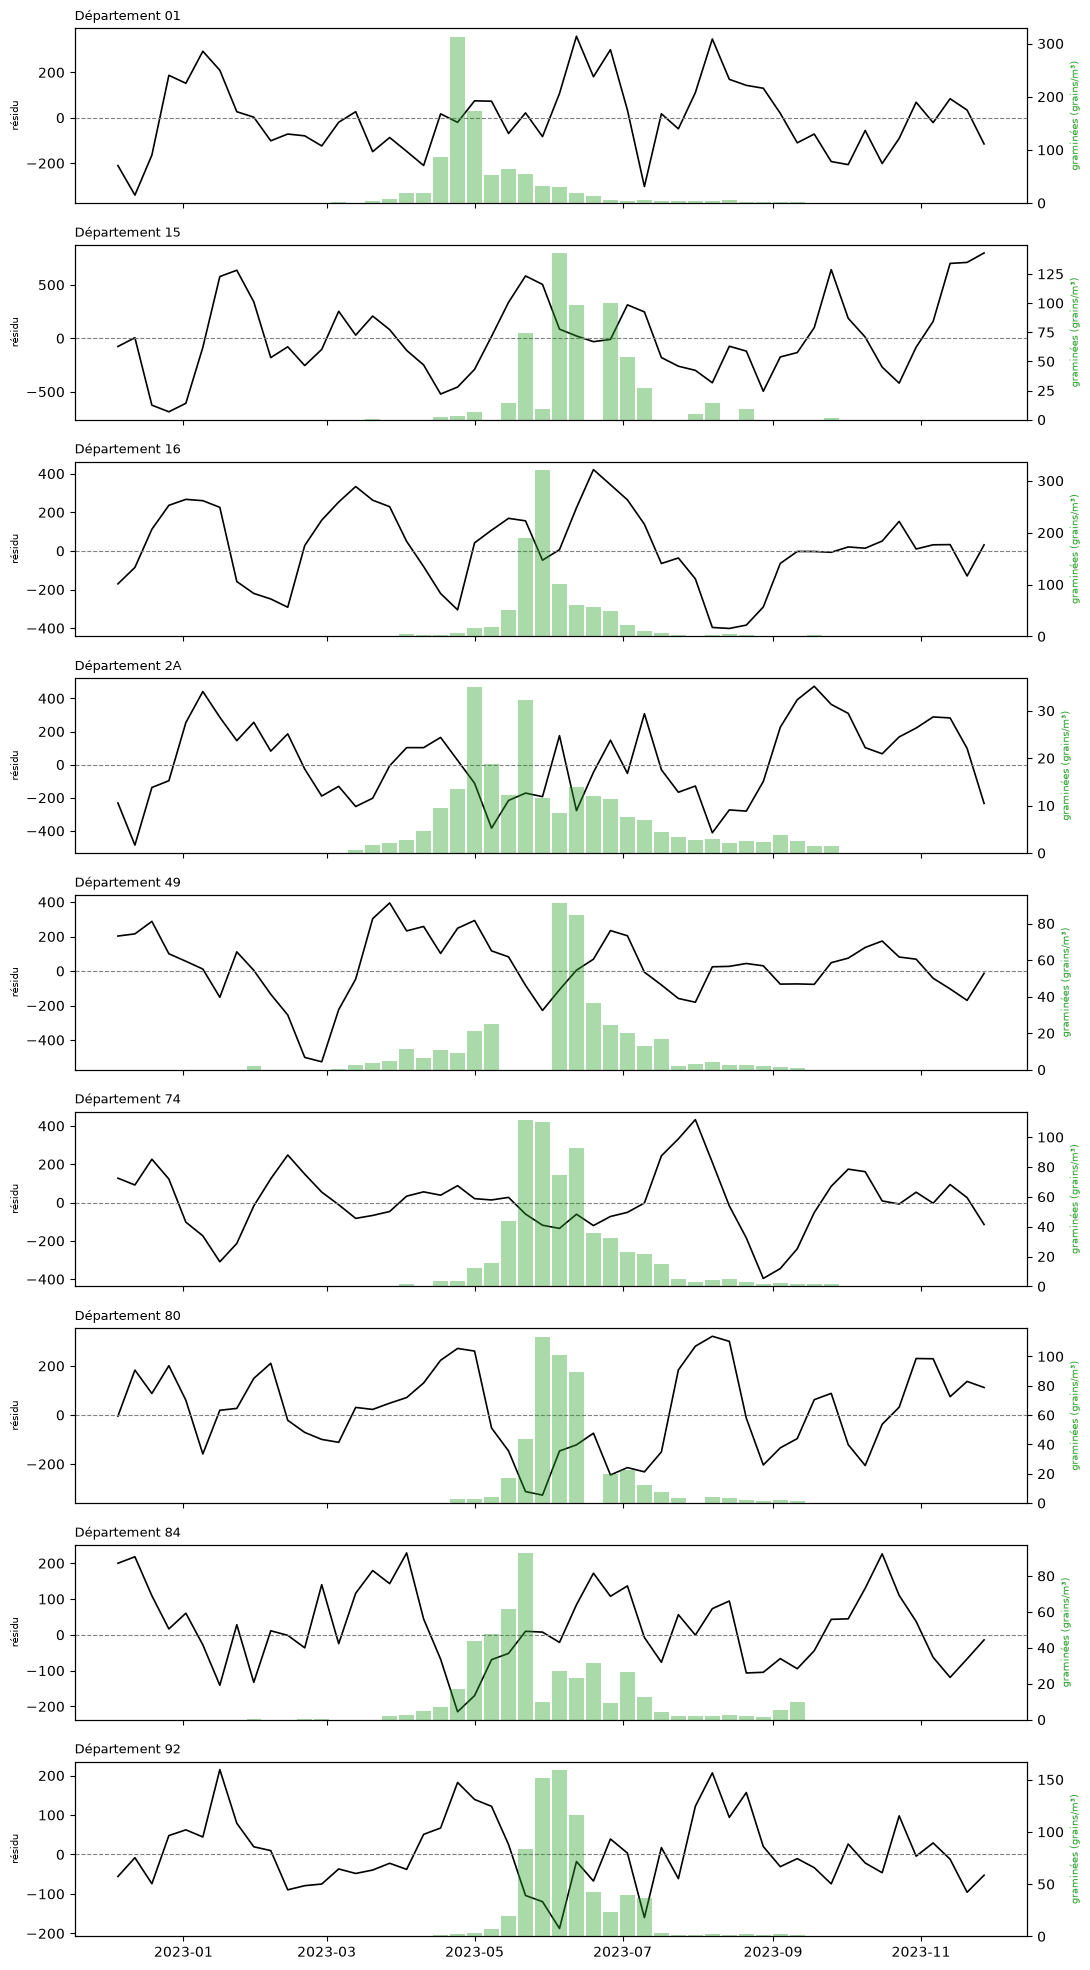

In [11]:
depts = sorted(pol_h["code_dept"].unique())
fig, axes = plt.subplots(len(depts), 1, figsize=(11, 2.2 * len(depts)), sharex=True)
for ax, dept in zip(axes, depts):
    r = r23[r23["code_dept"] == dept].set_index("date")["residu"]
    x = pol_h[pol_h["code_dept"] == dept].set_index("date")["pollen"].loc["2023"]
    ax.plot(r.index, r, color="black", lw=1.2)
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_ylabel("résidu", fontsize=7)
    ax2 = ax.twinx()
    ax2.bar(x.index, x, width=6, color="tab:green", alpha=0.4)
    ax2.set_ylabel("graminées (grains/m³)", fontsize=7, color="tab:green")
    ax.set_title(f"Département {dept}", fontsize=9, loc="left")
plt.tight_layout()
plt.show()

In [12]:
BLOC = 4

v = p.loc[p["split"] == "val"].rename_axis("date").reset_index()
v["anom"] = v["cible"] - v["saison_cible"]
v["anom_passe"] = v["y_passe"] - v["saison_y_passe"]

lignes = []
for dept, pd_ in pol_h.groupby("code_dept"):
    x = np.log1p(pd_.set_index("date")["pollen"].asfreq("W-MON"))
    t = v[v["code_dept"] == dept].set_index("date").sort_index()
    t = t.assign(pollen=x.reindex(t.index), delta=(x - x.shift(2)).reindex(t.index))
    t = t.dropna(subset=["anom", "anom_passe", "pollen", "delta"])
    if len(t) < 2 * BLOC:
        continue

    y = t["anom"].to_numpy()
    X = np.column_stack([np.ones(len(t)), t["pollen"], t["delta"]])
    blocs = np.arange(len(t)) // BLOC
    pred_pol = np.full(len(t), np.nan)
    for b in np.unique(blocs):
        test = blocs == b
        beta, *_ = np.linalg.lstsq(X[~test], y[~test], rcond=None)
        pred_pol[test] = X[test] @ beta

    rmse = lambda e: np.sqrt(np.mean(e ** 2))
    lignes.append({"code_dept": dept, "n": len(t),
                   "rmse_saison":         rmse(y),
                   "rmse_saison_persist": rmse(y - t["anom_passe"].to_numpy()),
                   "rmse_saison_pollen":  rmse(y - pred_pol)})

comp = pd.DataFrame(lignes).set_index("code_dept").round(1)
display(comp)
print("Pollen meilleur que persistance :",
      (comp["rmse_saison_pollen"] < comp["rmse_saison_persist"]).sum(), "/", len(comp))

,n,rmse_saison,rmse_saison_persist,rmse_saison_pollen
code_dept,,,,
01,35,146.7,148.6,153.2
15,8,231.7,258.5,326.2
16,36,200.2,217.6,160.4
2A,27,431.2,234.9,229.9
49,21,105.5,185.3,107.1
74,23,129.1,191.5,172.7
80,15,131.6,201.0,108.0
84,26,156.2,95.0,113.4
92,26,85.7,101.6,69.4


Pollen meilleur que persistance : 6 / 9


In [13]:
import re, unicodedata

STATION_DEPT = {"AGEN": "47", "AIXENPROVENCE": "13", "AJACCIO": "2A", "ALES": "30",
    "AMBERIEU": "01", "AMIENS": "80", "ANGERS": "49", "ANGOULEME": "16", "ANNECY": "74",
    "ANNEMASSE": "74", "ANTONY": "92", "AURILLAC": "15", "AUXERRE": "89", "AVIGNON": "84",
    "BAGNOLS": "30", "BART": "25", "BAYONNE": "64", "BERRIAS": "07", "BESANCON": "25",
    "BLETTERANS": "39", "BORDEAUX": "33", "BORDEAUXBASSENS": "33", "BORDEAUXPESSAC": "33",
    "BOURGENBRESSE": "01", "BOURGES": "18", "BOURGOINJALLIEU": "38", "BRESTREG": "29",
    "BRIANCON": "05", "BRUSSIEULANZONI": "69", "CAEN": "14", "CASTRES": "81",
    "CHALONSURSAONE": "71", "CHAMBERY": "73", "CHARLEVILLE": "08", "CHAUMONT": "52",
    "CHOLET": "49", "CLERMONTFERRAND": "63", "CORTE": "2B", "COUX": "07", "DIEULEFIT": "26",
    "DIJON": "21", "DINAN": "22", "DOLE": "39", "DRAGUIGNAN": "83", "DURAS": "47",
    "FONTROMEU": "66", "FUMEL": "47", "GAP": "05", "GENAS": "69", "GLEIZE": "69", "GONESSE": "95",
    "GRENOBLE": "38", "LABOURBOULE": "63", "LAFERTEMACE": "61", "LAFLECHE": "72",
    "LAROCHELLE": "17", "LAROCHESURYON": "85", "LEMANS": "72", "LEPUYENVELAY": "43", "LILLE": "59",
    "LIMOGES": "87", "LORIENT": "56", "LURE": "70", "LYON": "69", "LYONSITE": "69",
    "LYONWESTCRAPONNE": "69", "MACON": "71", "MAREUIL": "24", "MARSEILLE": "13", "MELUN": "77",
    "METZ": "57", "MILLAU": "12", "MONTDEMARSAN": "40", "MONTLUCON": "03", "MONTPELLIER": "34",
    "MULHOUSE": "68", "NANCY": "54", "NANTES": "44", "NARBONNE": "11", "NERAC": "47",
    "NEVERS": "58", "NICE": "06", "NIMES": "30", "NIORT": "79", "ORLEANS": "45", "PARIS": "75",
    "PAU": "64", "PERIGEUX": "24", "PERPIGNAN": "66", "PICDUMIDI": "65", "POITIERS": "86",
    "PONTIVY": "56", "REIMS": "51", "RENNES": "35", "ROANNE": "42", "ROUEN": "76",
    "ROUSSILLON": "38", "RUFFEC": "16", "SACLAY": "91", "SAINTALBANAURIOLLES": "07",
    "SAINTBRIEUC": "22", "SAINTDIEDESVOSGES": "88", "SAINTEFOYLESLYON": "69", "SAINTETIENNE": "42",
    "SAINTOMER": "62", "SAINTQUENTINENYVELINES": "78", "SEDAN": "08", "SIGNYLABBAYE": "08",
    "STGENIS": "69", "STQUENTIN": "02", "STRASBOURG": "67", "TARBES": "65", "TOULON": "83",
    "TOULOUSE": "31", "TOURS": "37", "TROYES": "10", "TULLE": "19", "VALDAHON": "25",
    "VALENCE": "26", "VERNETLESBAINS": "66", "VICHY": "03", "VILLENEUVEDASCQ": "59"}

def norm(nom):
    nom = unicodedata.normalize("NFKD", str(nom)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Z]", "", nom.upper())

FICHIERS = ["../data/processed/POLLEN2021.csv", "../data/processed/POLLEN2022.csv",
            "../data/processed/POLLEN2023.csv"]

def lire_pollens(chemin):
    t = pd.read_csv(chemin, sep=";", decimal=",")
    t = t.rename(columns={t.columns[0]: "date"})
    fmt = "%d/%m/%Y" if "/" in str(t["date"].iloc[0]) else "%Y-%m-%d"
    t["date"] = pd.to_datetime(t["date"], format=fmt)
    return t.melt(id_vars="date", var_name="ville", value_name="pollen")

pol = pd.concat([lire_pollens(f) for f in FICHIERS])
pol["code_dept"] = pol["ville"].map(norm).map(STATION_DEPT)
print("Villes sans département :", sorted(pol.loc[pol["code_dept"].isna(), "ville"].unique()))

pol_h = (pol.dropna(subset=["code_dept", "pollen"])
         .groupby(["code_dept", pd.Grouper(key="date", freq="W-MON", label="left", closed="left")])
         ["pollen"].agg(["mean", "count"]))
pol_h = pol_h.loc[pol_h["count"] >= 4, "mean"].rename("pollen").reset_index()
print(pol_h.groupby(pol_h["date"].dt.year)["code_dept"].nunique().rename("départements par an"))

p = panel.copy()
p["sem"] = p.index.isocalendar().week.values
prof = (p[p["split"] == "train"].groupby(["code_dept", "sem"])[["cible", "y_passe"]]
        .mean().add_prefix("saison_"))
p = p.join(prof, on=["code_dept", "sem"])
p["anom"] = p["cible"] - p["saison_cible"]
p["anom_passe"] = p["y_passe"] - p["saison_y_passe"]
p = p.rename_axis("date").reset_index()

rmse = lambda e: np.sqrt(np.mean(e ** 2))
def ajuste(X_app, y_app, X_test):
    beta, *_ = np.linalg.lstsq(X_app, y_app, rcond=None)
    return X_test @ beta

lignes = []
for dept, pd_ in pol_h.groupby("code_dept"):
    x = np.log1p(pd_.set_index("date")["pollen"].asfreq("W-MON"))
    t = p[p["code_dept"] == dept].set_index("date").sort_index()
    t = t.assign(pollen=x.reindex(t.index), delta=(x - x.shift(2)).reindex(t.index))
    t = t.dropna(subset=["anom", "anom_passe", "pollen", "delta"])
    app, test = t[t["split"] == "train"], t[t["split"] == "val"]
    if len(app) < 10 or len(test) < 5:
        continue

    un = lambda d: np.ones((len(d), 1))
    X_pol  = lambda d: np.column_stack([un(d), d["pollen"], d["delta"]])
    X_tout = lambda d: np.column_stack([un(d), d["anom_passe"], d["pollen"], d["delta"]])
    X_pers = lambda d: np.column_stack([un(d), d["anom_passe"]])
    y_app, y_test = app["anom"].to_numpy(), test["anom"].to_numpy()

    lignes.append({"code_dept": dept, "n_train": len(app), "n_test": len(test),
                   "saison":                 rmse(y_test),
                   "saison_persist":         rmse(y_test - test["anom_passe"].to_numpy()),
                   "saison_pollen":          rmse(y_test - ajuste(X_pol(app), y_app, X_pol(test))),
                   "saison_persist_ajust":   rmse(y_test - ajuste(X_pers(app), y_app, X_pers(test))),
                   "saison_persist_pollen":  rmse(y_test - ajuste(X_tout(app), y_app, X_tout(test)))})

comp3 = pd.DataFrame(lignes).set_index("code_dept").round(1)
display(comp3)
modeles = ["saison", "saison_persist", "saison_pollen", "saison_persist_pollen"]
print("Meilleur modèle par département :\n", comp3[modeles].idxmin(axis=1).value_counts())

Villes sans département : []
date
2021    9
2022    9
2023    9
Name: départements par an, dtype: int64


,n_train,n_test,saison,saison_persist,saison_pollen,saison_persist_ajust,saison_persist_pollen
code_dept,,,,,,,
01,13,35,146.7,148.6,144.1,155.0,143.9
15,21,8,231.7,258.5,232.4,235.6,211.9
16,72,36,200.2,217.6,194.6,182.5,179.5
2A,45,27,431.2,234.9,427.4,226.8,228.2
49,45,21,105.5,185.3,122.7,105.9,124.8
74,61,23,129.1,191.5,126.8,149.8,146.8
80,35,15,131.6,201.0,140.2,153.3,158.4
84,52,26,156.2,95.0,156.1,94.6,95.8
92,43,26,85.7,101.6,75.9,80.2,73.8


Meilleur modèle par département :
 saison_persist_pollen    5
saison                   2
saison_pollen            1
saison_persist           1
Name: count, dtype: int64


In [14]:
Q_PIC = 0.75

lignes = []
for dept, pd_ in pol_h.groupby("code_dept"):
    x = np.log1p(pd_.set_index("date")["pollen"].asfreq("W-MON"))
    t = p[p["code_dept"] == dept].set_index("date").sort_index()
    t = t.assign(pollen=x.reindex(t.index), delta=(x - x.shift(2)).reindex(t.index))
    t = t.dropna(subset=["anom", "anom_passe", "pollen", "delta"])
    app, test = t[t["split"] == "train"], t[t["split"] == "val"]
    if len(app) < 10 or len(test) < 5:
        continue
    seuil = app["pollen"].quantile(Q_PIC)
    app, test = app.assign(pic=(app["pollen"] > seuil) * 1.0), test.assign(pic=(test["pollen"] > seuil) * 1.0)

    un = lambda d: np.ones((len(d), 1))
    X_pers = lambda d: np.column_stack([un(d), d["anom_passe"]])
    X_tout = lambda d: np.column_stack([un(d), d["anom_passe"], d["pollen"], d["delta"]])
    X_pic  = lambda d: np.column_stack([un(d), d["anom_passe"], d["pic"], d["delta"]])
    y_app, y_test = app["anom"].to_numpy(), test["anom"].to_numpy()
    preds = {"persist_ajust": ajuste(X_pers(app), y_app, X_pers(test)),
             "persist_pollen": ajuste(X_tout(app), y_app, X_tout(test)),
             "persist_pic": ajuste(X_pic(app), y_app, X_pic(test))}

    enpic = test["pic"].to_numpy() == 1
    ligne = {"code_dept": dept, "n_test": len(test), "n_sem_pic": int(enpic.sum())}
    for nom, pr in preds.items():
        ligne[f"{nom}_toutes"] = rmse(y_test - pr)
        ligne[f"{nom}_pics"] = rmse(y_test[enpic] - pr[enpic]) if enpic.sum() >= 2 else np.nan
    lignes.append(ligne)

pics = pd.DataFrame(lignes).set_index("code_dept").round(1)
display(pics)

,n_test,n_sem_pic,persist_ajust_toutes,persist_ajust_pics,persist_pollen_toutes,persist_pollen_pics,persist_pic_toutes,persist_pic_pics
code_dept,,,,,,,,
01,35,22,155.0,178.9,143.9,165.0,151.2,177.6
15,8,3,235.6,129.0,211.9,82.8,229.2,95.5
16,36,7,182.5,253.1,179.5,245.0,180.5,244.0
2A,27,2,226.8,168.1,228.2,188.0,226.5,186.1
49,21,5,105.9,164.1,124.8,214.4,121.3,214.6
74,23,11,149.8,111.4,146.8,101.6,143.9,94.5
80,15,4,153.3,70.7,158.4,81.2,159.3,87.4
84,26,7,94.6,103.5,95.8,107.9,97.7,102.7
92,26,4,80.2,50.9,73.8,44.8,74.1,44.6
